# 

### El proposito de este notebook fue probar ACOLITE y entender como utilizarlo
### La implmentacion final se encuentra en @tools/ac/acolite.py

In [58]:
import argparse
import json
import os
import shutil
import sys
import zipfile
from pathlib import Path

import geopandas as gpd
import numpy as np
import pandas as pd
import pystac
import requests
import xarray as xr
from dotenv import load_dotenv
from pyproj import Transformer
from tqdm.auto import tqdm
sys.path.append("../../external/acolite")
import acolite as ac

In [2]:
SAFE_DIR = Path("safe")

In [ ]:
scene_df = pd.read_csv("../../data/nuevos/l1c_scene_products.csv")
ZIPPER = "https://zipper.dataspace.copernicus.eu/odata/v1/Products({id})/$value"

In [7]:
SCENE_MARGIN_DEG = 0.05   # ~5 km around the matchups: room for dark pixels (DSF)
POINT_HALF_WIN = 2

In [12]:
scene_df.shape

(529, 3)

In [9]:
scene_df.head(2)

,name,id,online
0,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,d4d98e81-e795-4059-861d-611143221276,True
1,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,1963fc63-9e81-4cbc-a27a-5f951e6c280b,True


In [22]:
def cdse_token() -> str:
    TOKEN_URL = "https://identity.dataspace.copernicus.eu/auth/realms/CDSE/protocol/openid-connect/token"
    from dotenv import load_dotenv
    load_dotenv()
    r = requests.post(TOKEN_URL, data={
        "grant_type": "password",
        "client_id": "cdse-public",
        "username": os.environ["CDSE_USERNAME"],
        "password": os.environ["CDSE_PASSWORD"],
    }, timeout=60)
    r.raise_for_status()
    return r.json()["access_token"]

In [23]:
def download_safe(l1c: dict) -> Path:
    safe_path = SAFE_DIR / l1c["name"]
    if safe_path.exists():
        return safe_path
    SAFE_DIR.mkdir(parents=True, exist_ok=True)
    zip_path = SAFE_DIR / (l1c["name"] + ".zip")

    session = requests.Session()
    session.headers["Authorization"] = f"Bearer {cdse_token()}"  # tokens last ~10 min
    url = ZIPPER.format(id=l1c["id"])
    # follow redirects by hand so the auth header is kept
    r = session.get(url, allow_redirects=False, stream=True, timeout=120)
    while r.status_code in (301, 302, 303, 307, 308):
        url = r.headers["Location"]
        r = session.get(url, allow_redirects=False, stream=True, timeout=120)
    r.raise_for_status()

    total = int(r.headers.get("Content-Length", 0))
    with open(zip_path, "wb") as f, tqdm(total=total, unit="B", unit_scale=True,
                                         desc=l1c["name"][:38], leave=False) as bar:
        for chunk in r.iter_content(chunk_size=8 * 1024 * 1024):
            f.write(chunk)
            bar.update(len(chunk))

    with zipfile.ZipFile(zip_path) as z:
        z.extractall(SAFE_DIR)
    zip_path.unlink()
    return safe_path

In [25]:
download_safe(df.iloc[0].to_dict())

PosixPath('safe/S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_20230923T131421.SAFE')

In [48]:
matchups = gpd.read_file("../../data/nuevos/matchups_registros_finales.geojson")
to_wgs84 = Transformer.from_crs("EPSG:32721", "EPSG:4326", always_xy=True)
lon, lat = to_wgs84.transform(matchups.geometry.x.values, matchups.geometry.y.values)
matchups = pd.DataFrame({"pass_id": matchups["pass_id"].values, "lat": lat, "lon": lon})
matchups.head(2)

,pass_id,lat,lon
0,S2A_MSIL1C_20170104T135052_N0500_R024_T21HUC_2...,-34.205076,-58.072809
1,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.795008,-55.050169


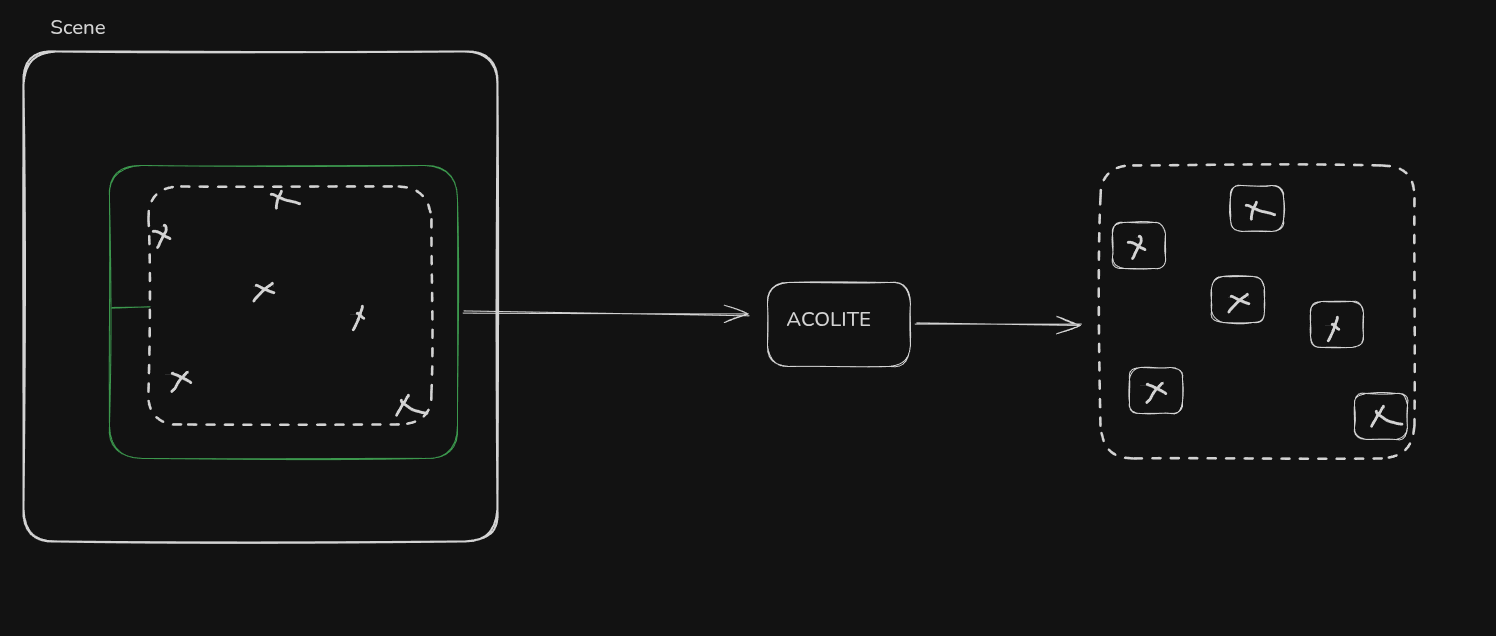

In [22]:
from IPython.display import Image, display
display(Image("scenes_to_windows.png"))

In [49]:
id_1 = scene_df["name"].iloc[0][:-5]

In [ ]:
# para cada escena [x]
# agarramos todos los puntos de esa escena [x]
# con esos puntos calculas el bonding box 
# acolite
# ventana para cada punto

In [50]:
puntos_escena = matchups[matchups["pass_id"] == id_1]
puntos_escena

,pass_id,lat,lon
1,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.795008,-55.050169
2,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.829733,-55.042069
5,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.841008,-55.068342
6,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.842672,-55.143344
8,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.764606,-55.078086
9,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.843169,-55.120006
11,S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_2...,-34.748703,-55.041242


In [54]:
margin = 0.05 # 5 km
resolution = 20

In [55]:
box = [puntos_escena["lat"].min() - margin, puntos_escena["lon"].min() - margin,
        puntos_escena["lat"].max() + margin, puntos_escena["lon"].max() + margin]
box

[np.float64(-34.893169),
 np.float64(-55.193344),
 np.float64(-34.698702999999995),
 np.float64(-54.991242)]

In [37]:
puntos_escena.y.min()

np.float64(6142737.153054101)

In [61]:
settings = {
    "inputfile": "safe/S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_20230923T131421.SAFE",
    "output": "acolite-output",
    "limit": box,                          # S, W, N, E
    "s2_target_res": 20,
    "dsf_aot_estimate": "fixed",             # small ROI -> one AOT for the box
    "dsf_residual_glint_correction": True,
    "l2w_parameters": "rhow_*",
    "l2w_mask_threshold": 0.05,
    "rgb_rhot": True,                        # quick-look to eyeball clouds
    "map_l2w": False,
    "l1r_delete_netcdf": True,  
}

In [62]:
ac.acolite.acolite_run(settings=settings)

/home/enzotrindade/ProyectoAA/notebooks/09_acolite/../../external/acolite/acolite/sentinel2/l1_convert.py:398: RuntimeWarning: Mean of empty slice
  ave_vza = np.nanmean(ave_vza, axis=2)
/home/enzotrindade/ProyectoAA/notebooks/09_acolite/../../external/acolite/acolite/sentinel2/l1_convert.py:399: RuntimeWarning: Mean of empty slice
  ave_vaa = np.nanmean(ave_vaa, axis=2)


{0: {'input': 'safe/S2A_MSIL1C_20161229T133222_N0500_R081_T21HXB_20230923T131421.SAFE',
  'l1r': ['acolite-output/S2A_MSI_2016_12_29_13_42_05_T21HXB_L1R.nc'],
  'l2r': ['acolite-output/S2A_MSI_2016_12_29_13_42_05_T21HXB_L2R.nc'],
  'l2w': ['acolite-output/S2A_MSI_2016_12_29_13_42_05_T21HXB_L2W.nc']}}